# Representar incertidumbre con una distribución
### Actividad guiada

En clase, comentabamos algo que suena sencillo, pero que en realidad es bastante más profundo: en el setting estandar de Bayesiana, **el parámetro $\theta$ es un número fijo, pero yo no lo conozco, y lo que no sé sobre él (o lo que creo saber) lo escribo como una distribución**.

Luego, vimos que actualizar de manera racional esas creencias (esa distribución) con datos se reduce a una receta de tres pasos:

$$\text{posterior} \;\propto\; \text{verosimilitud} \times \text{prior}, \qquad \text{y al final se normaliza.}$$

En esta actividad vamos a tomar esa receta y a verla funcionar en cinco situaciones, de la más boba a una con datos históricos reales, para que quede claro **qué significa, en la práctica, representar incertidumbre con una distribución**.

| Parte | Situación | Idea que se lleva | Tiempo |
|---|---|---|---|
| 1 | Un dado: ¿justo o cargado? | dos hipótesis; el dado ya es lo que es, la incertidumbre es nuestra | 20 min |
| 2 | Las canicas de McElreath | la verosimilitud es literalmente **contar** | 15 min |
| 3 | El globo terráqueo | de cinco hipótesis a una rejilla; probabilidad contra densidad; el prior importa | 30 min |
| 4 | Laplace y los nacimientos de París | datos reales enormes: logaritmos, y el prior casi deja de importar | 20 min |
| 5 | Una clínica pequeña | pocos datos: el contexto entra por el prior | 15 min |

**Cómo usar este notebook.** No hay nada que completar. Se corre celda por celda, y antes de varias celdas hay una pregunta del tipo *"antes de correr, ¿qué esperan?"*. Vale la pena contestarla en voz alta (o en papel) **antes** de ver el resultado: equivocarse en la predicción es justamente donde se aprende. Si faltaste a la sesión, puedes recorrerlo solo de principio a fin; está escrito para eso.

**Referencias.** McElreath, *Statistical Rethinking* (2a ed.), cap. 2 (canicas y globo). Gelman et al., *Bayesian Data Analysis* (3a ed., BDA3), cap. 2 (Laplace y la proporción de niñas al nacer).



In [14]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import product
from scipy import stats

# Paleta del curso (la misma de las slides)
C_SLATE = "#283747"   # neutro / prior
C_TEAL  = "#169685"   # posterior
C_WARN  = "#b03a2e"   # alerta
C_GOLD  = "#bc8e3a"   # verosimilitud / acento

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.25, "font.size": 11})

---
## Parte 1. Un dado: dos tipos de incertidumbre

Empecemos con lo más simple que existe. Tengo **dos dados** que se ven idénticos:

- el **justo**: cada cara sale con probabilidad $1/6$;
- el **cargado**, sutilmente: el 6 sale con probabilidad $1/3$ y cada una de las otras cinco caras con $2/15$.

Cada dado, por sí mismo, es un modelo de cómo se generan los tiros: una distribución sobre las caras $\{1,\dots,6\}$. Esa es la primera incertidumbre, la que ya conocen: **¿qué cara va a salir?** 

> No se puede saber con certeza. Solo conocemos la distribución de probabilidad sobre las caras.

Suma de probabilidades, justo:   1.0000
Suma de probabilidades, cargado: 1.0000


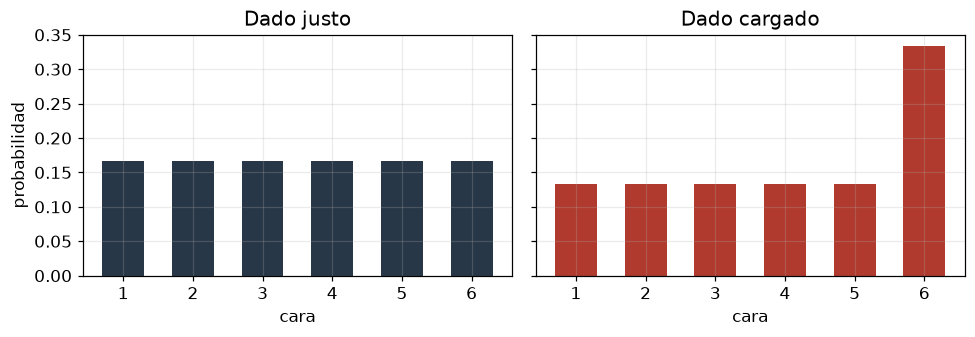

In [15]:
caras = np.arange(1, 7)
dado_justo   = np.full(6, 1/6)
dado_cargado = np.array([2/15, 2/15, 2/15, 2/15, 2/15, 1/3])

print(f"Suma de probabilidades, justo:   {dado_justo.sum():.4f}")
print(f"Suma de probabilidades, cargado: {dado_cargado.sum():.4f}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, p, nombre, c in [(axes[0], dado_justo, "Dado justo", C_SLATE),
                         (axes[1], dado_cargado, "Dado cargado", C_WARN)]:
    ax.bar(caras, p, color=c, width=0.6)
    ax.set_title(nombre); ax.set_xlabel("cara"); ax.set_xticks(caras)
axes[0].set_ylabel("probabilidad")
plt.tight_layout(); plt.show()

Ahora la segunda incertidumbre, que es la que nos interesa en esta parte del curso. Alguien toma **uno** de los dos dados, sin decirnos cuál, y empieza a tirarlo.

El dado que escogió **ya es** el justo o el cargado; ahí no hay nada aleatorio. Lo que pasa es que **nosotros no sabemos cuál es**. Esa ignorancia es lo que vamos a describir con una distribución, ahora sobre las dos hipótesis:

$$H_J = \text{"es el justo"}, \qquad H_C = \text{"es el cargado"}.$$

Para poder comprobar si el método funciona, vamos a **jugar a ser la naturaleza**: escogemos nosotros el dado en secreto y simulamos los tiros. El analista (o sea, ustedes dentro de cinco minutos) solo ve la lista de tiros.

In [16]:
rng = np.random.default_rng(7)      # semilla fija: todos vemos los mismos tiros

dado_secreto = dado_cargado         # la naturaleza escoge. El analista NO ve esta línea.
n_tiros = 200
tiros = rng.choice(caras, size=n_tiros, p=dado_secreto)

print("Primeros 30 tiros:", tiros[:30])
print("¿Cuántos 6 en los primeros 30?", (tiros[:30] == 6).sum(), " (un dado justo daría unos 5)")

Primeros 30 tiros: [5 6 6 2 3 6 1 6 6 4 3 3 2 4 4 5 6 6 5 6 2 2 5 1 1 4 4 6 5 4]
¿Cuántos 6 en los primeros 30? 9  (un dado justo daría unos 5)


### Paso a paso: un tiro a la vez

Es exactamente la tabla del corrector ortográfico, pero con dos renglones y repetida en cada tiro:

| hipótesis | prior | verosimilitud del tiro | producto | posterior |
|---|---|---|---|---|
| $H_C$ | $P(H_C)$ | $P(\text{cara}\mid H_C)$ | prior $\times$ verosimilitud | producto / suma |
| $H_J$ | $P(H_J)$ | $P(\text{cara}\mid H_J)$ | prior $\times$ verosimilitud | producto / suma |

Fíjense en qué hace cada tiro:

- si sale un **6**, la verosimilitud favorece al cargado: $\frac{1/3}{1/6} = 2$ veces más probable bajo $H_C$;
- si sale **otra cara**, favorece un poquito al justo: $\frac{2/15}{1/6} = 0.8$.

Entonces cada 6 empuja hacia "cargado" y cada no-6 empuja, más suavemente, hacia "justo".

**Antes de correr:** empezando en $P(H_C)=0.5$, después de los primeros doce tiros de arriba, ¿creen que ya estaremos convencidos? 

> Sí, porque si el dado es el cargado, tenderán a salir más seises, y cada 6 aumenta la probabilidad posterior de ‘cargado’. Por lo que será más marcada la distinción entre qué dado podríamos estar utilizando. 

In [17]:
def actualiza(p_cargado, cara):
    '''Un paso de Bayes con dos hipótesis.
    Entra: P(cargado) antes del tiro y la cara observada.
    Sale:  P(cargado) después del tiro.'''
    v_c = dado_cargado[cara - 1]          # verosimilitud si es el cargado
    v_j = dado_justo[cara - 1]            # verosimilitud si es el justo
    prod_c = v_c * p_cargado              # multiplicar...
    prod_j = v_j * (1 - p_cargado)
    return prod_c / (prod_c + prod_j)     # ...y normalizar

p = 0.5
print(f"{'tiro':>4} {'cara':>5}   P(cargado | tiros hasta aquí)")
print(f"{'':>4} {'':>5}   {p:.3f}   (prior)")
for i, cara in enumerate(tiros[:12], start=1):
    p = actualiza(p, cara)
    print(f"{i:>4} {cara:>5}   {p:.3f}")

tiro  cara   P(cargado | tiros hasta aquí)
             0.500   (prior)
   1     5   0.444
   2     6   0.615
   3     6   0.762
   4     2   0.719
   5     3   0.672
   6     6   0.804
   7     1   0.766
   8     6   0.868
   9     6   0.929
  10     4   0.913
  11     3   0.893
  12     3   0.870


Noten tres cosas en la tabla:

1. La creencia **sube y baja**. Ningún tiro aislado decide nada; cada uno mueve un poco la balanza.
2. El posterior de un tiro se vuelve el prior del siguiente. No hay ninguna regla nueva: es la misma multiplicación, encadenada.
3. Doce tiros dan alguna evidencia, pero estamos lejos de la certeza. El dado está cargado de forma sutil, y eso cuesta datos.

### Dos personas, mismos tiros, distinto prior

Ahora pongamos a dos analistas a ver **los mismos 200 tiros**:

- la **neutral**, que empieza con $P(H_C)=0.5$;
- el **confiado**, que piensa: "en este casino casi ningún dado está cargado; digamos 1 de cada 1000". Empieza con $P(H_C)=0.001$.

**Antes de correr:** ¿llegarán al mismo lugar? ¿Cuándo?

> Si deberían llegar al mismo lugar pero en diferentes momentos. Ya que, parten de diferentes puntos, por lo que el recorrido tomará más tiempo para el confiado. 

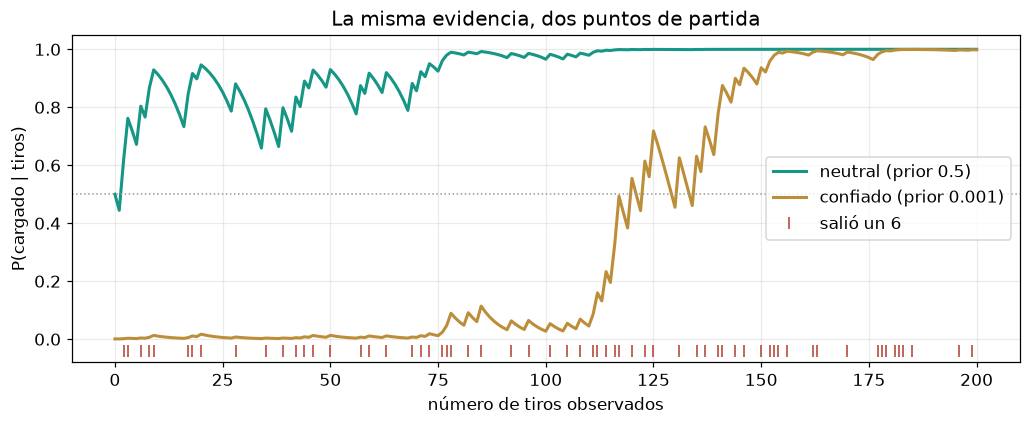

después de  12 tiros:  neutral 0.870   confiado 0.007
después de  60 tiros:  neutral 0.899   confiado 0.009
después de 120 tiros:  neutral 0.999   confiado 0.554
después de 200 tiros:  neutral 1.000   confiado 0.998


In [18]:
def trayectoria(prior, datos):
    ps = [prior]
    for cara in datos:
        ps.append(actualiza(ps[-1], cara))
    return np.array(ps)

tr_neutral  = trayectoria(0.5,   tiros)
tr_confiado = trayectoria(0.001, tiros)

fig, ax = plt.subplots(figsize=(9.5, 4))
ax.plot(tr_neutral,  color=C_TEAL, lw=2, label="neutral (prior 0.5)")
ax.plot(tr_confiado, color=C_GOLD, lw=2, label="confiado (prior 0.001)")
seis = np.where(tiros == 6)[0] + 1
ax.plot(seis, np.full_like(seis, -0.04, dtype=float), "|", color=C_WARN, ms=8, label="salió un 6")
ax.axhline(0.5, color="0.6", ls=":", lw=1)
ax.set_xlabel("número de tiros observados"); ax.set_ylabel("P(cargado | tiros)")
ax.set_ylim(-0.08, 1.05); ax.legend(loc="center right")
ax.set_title("La misma evidencia, dos puntos de partida")
plt.tight_layout(); plt.show()

for t in [12, 60, 120, 200]:
    print(f"después de {t:>3} tiros:  neutral {tr_neutral[t]:.3f}   confiado {tr_confiado[t]:.3f}")

**¿Qué pasó?**

- Con pocos datos, el prior **pesa muchísimo**: a los 60 tiros la neutral ya sospecha fuerte, y el confiado sigue casi tranquilo. Ninguno de los dos está siendo irracional; empezaron de lugares distintos.
- Con suficientes datos, las dos creencias **convergen**. Los datos acaban mandando, pero el prior decide cuántos datos hacen falta para convencerte.
- Las rayitas rojas muestran la mecánica: cada racha de seises dispara las curvas hacia arriba, y cada racha sin seises las deja bajar despacio.

### ¿Importa si actualizo de uno en uno o todo de golpe?

En lugar de 200 actualizaciones, puedo hacer una sola: la verosimilitud de **todos** los tiros juntos es el producto de las verosimilitudes individuales (los tiros son independientes dado el dado). Bajo $H_C$ eso es $(1/3)^{\#6}\,(2/15)^{\#\text{otros}}$; bajo $H_J$ es $(1/6)^{200}$.

In [19]:
n6     = (tiros == 6).sum()
n_otro = n_tiros - n6

ver_C = (1/3)**n6 * (2/15)**n_otro       # P(los 200 tiros | cargado)
ver_J = (1/6)**n_tiros                   # P(los 200 tiros | justo)
print(f"número de seises: {n6} de {n_tiros}")
print(f"P(datos | cargado) = {ver_C:.3e}")
print(f"P(datos | justo)   = {ver_J:.3e}")

prior_C = 0.5
post_lote = ver_C * prior_C / (ver_C * prior_C + ver_J * (1 - prior_C))
print(f"\nPosterior en un solo paso:     {post_lote:.6f}")
print(f"Posterior tiro por tiro:       {tr_neutral[-1]:.6f}")

# Y si los tiros hubieran llegado en otro orden?
tiros_revueltos = rng.permutation(tiros)
print(f"Tiro por tiro, orden revuelto: {trayectoria(0.5, tiros_revueltos)[-1]:.6f}")

número de seises: 63 de 200
P(datos | cargado) = 1.143e-150
P(datos | justo)   = 2.343e-156

Posterior en un solo paso:     0.999998
Posterior tiro por tiro:       0.999998
Tiro por tiro, orden revuelto: 0.999998


Los tres números coinciden. **Actualizar de uno en uno, todo de golpe, o en otro orden, da lo mismo.** Esto conecta con la coherencia de la sesión: si el orden en que te llegan los datos cambiara tu conclusión final, alguien podría explotarte.

Y fíjense en el tamaño de las verosimilitudes: números entre $10^{-156}$ y $10^{-150}$. Con 200 tiros todavía caben en la computadora. Guarden esa observación; en la Parte 4 nos va a explotar en la cara.

**Pregunta para el grupo.** ¿Puede la probabilidad de "cargado" llegar a ser **exactamente** 1 con estos datos? ¿Y qué pasaría si alguien empezara con prior $P(H_C) = 0$?

> No, con estos datos la probabilidad de "cargado" nunca llega a ser exactamente 1, porque ambos dados dan probabilidad positiva a cualquier secuencia, así que la posterior solo se acerca a 1 pero no logra alcanzarla.


## Parte 2. Las canicas: la verosimilitud es contar

Este ejemplo es de McElreath (*Statistical Rethinking*, §2.1). Hay una bolsa con **4 canicas**, cada una azul o blanca. No sabemos cuántas azules hay, así que hay cinco conjeturas posibles:

| conjetura | contenido (● azul, ○ blanca) |
|---|---|
| 0 azules | ○ ○ ○ ○ |
| 1 azul | ● ○ ○ ○ |
| 2 azules | ● ● ○ ○ |
| 3 azules | ● ● ● ○ |
| 4 azules | ● ● ● ● |

Sacamos una canica, anotamos su color, **la regresamos**, y repetimos. Salió: **azul, blanca, azul**.

La idea de McElreath es bellísima por lo simple: para cada conjetura, contemos **de cuántas maneras** se pudo haber producido exactamente lo que vimos. La computadora puede recorrer, para cada bolsa, todos los $4^3 = 64$ caminos posibles de tres extracciones.

In [20]:
bolsas = {k: ["azul"] * k + ["blanca"] * (4 - k) for k in range(5)}
observado = ("azul", "blanca", "azul")

def cuenta_caminos(bolsa, obs):
    '''Recorre TODOS los caminos posibles de sacar len(obs) canicas (con reemplazo)
    de esta bolsa, y cuenta cuántos producen exactamente la secuencia observada.'''
    total = 0
    for camino in product(bolsa, repeat=len(obs)):   # cada canica es distinguible
        if camino == obs:
            total += 1
    return total

caminos = np.array([cuenta_caminos(bolsas[k], observado) for k in range(5)])
plaus = caminos / caminos.sum()

print(f"{'azules':>6} {'caminos':>8} {'plausibilidad':>14}")
for k in range(5):
    print(f"{k:>6} {caminos[k]:>8} {plaus[k]:>14.2f}")

azules  caminos  plausibilidad
     0        0           0.00
     1        3           0.15
     2        8           0.40
     3        9           0.45
     4        0           0.00


Lean la tabla despacio:

- Con **0 azules** es imposible haber sacado una azul: cero caminos. Con **4 azules** es imposible haber sacado una blanca: cero caminos. Los datos **eliminaron** dos conjeturas.
- Con **1 azul**: hay 1 manera de sacar azul, 3 de sacar blanca, 1 de sacar azul: $1\times3\times1 = 3$. Con **3 azules**: $3\times1\times3 = 9$.
- Dividir entre el total convierte los conteos en probabilidades. Eso es **normalizar**.

### Llega una canica más: azul

**Antes de correr:** ¿hay que volver a contar todo desde cero, o basta con algo más sencillo?

> Debería ser más sencillo debido a que ya existe un antecedente de los eventos pasados. 

In [21]:
# Opción A: tomar los conteos viejos y multiplicarlos por las maneras de sacar UNA azul (= k)
maneras_azul = np.arange(5)
caminos_A = caminos * maneras_azul

# Opción B: contar desde cero con las cuatro extracciones
caminos_B = np.array([cuenta_caminos(bolsas[k], observado + ("azul",)) for k in range(5)])

print("Opción A (actualizar):     ", caminos_A)
print("Opción B (contar de nuevo):", caminos_B)

Opción A (actualizar):      [ 0  3 16 27  0]
Opción B (contar de nuevo): [ 0  3 16 27  0]


Idénticos. Los conteos viejos funcionan como **prior** de la nueva observación: es el mismo "el posterior de hoy es el prior de mañana" del dado.

### Información de otro lado

Ahora alguien de la fábrica nos dice: "las canicas azules son caras; por cada bolsa con 3 azules hacemos 2 con dos azules y 3 con una azul". Eso es información que **no** viene de nuestras extracciones. ¿Qué hacemos con ella? Lo mismo de siempre: multiplicar.

In [22]:
conteo_fabrica = np.array([0, 3, 2, 1, 0])     # cuántas bolsas de cada tipo produce la fábrica

nuevo = caminos_A * conteo_fabrica
print(f"{'azules':>6} {'datos':>6} {'fábrica':>8} {'producto':>9} {'plausibilidad':>14}")
for k in range(5):
    print(f"{k:>6} {caminos_A[k]:>6} {conteo_fabrica[k]:>8} {nuevo[k]:>9} {nuevo[k]/nuevo.sum():>14.2f}")

azules  datos  fábrica  producto  plausibilidad
     0      0        0         0           0.00
     1      3        3         9           0.13
     2     16        2        32           0.47
     3     27        1        27           0.40
     4      0        0         0           0.00


Antes de la fábrica ganaba "3 azules"; con la información de la fábrica gana "2 azules". Es el corrector ortográfico otra vez: **ni los datos ni el prior mandan solos; manda el producto**.

### De conjeturas a un parámetro

Cada conjetura se puede describir con un número: la **proporción de azules** $p = k/4 \in \{0, 0.25, 0.5, 0.75, 1\}$. Con eso, el conteo de caminos para "azul, blanca, azul" se puede escribir como fórmula:

$$\text{caminos} = (4p)\,(4(1-p))\,(4p) = 4^3\, p^2 (1-p).$$

Y $p^2(1-p)$ es, salvo una constante, la probabilidad binomial de ver esa secuencia si la proporción es $p$. **Contar caminos y calcular la verosimilitud son la misma cosa.** Comprobémoslo:

In [23]:
p_grid = np.arange(5) / 4
formula = 4**3 * p_grid**2 * (1 - p_grid)

print("p          :", p_grid)
print("contando   :", caminos)
print("fórmula    :", formula)
print("¿iguales?  :", np.allclose(caminos, formula))

p          : [0.   0.25 0.5  0.75 1.  ]
contando   : [0 3 8 9 0]
fórmula    : [0. 3. 8. 9. 0.]
¿iguales?  : True


Esta es la transición que hicimos en clase con el producto de Arca: las hipótesis dejan de ser "objetos" (palabras, bolsas, dados) y pasan a ser **valores de un parámetro**. Aquí hay cinco valores porque la bolsa tiene 4 canicas. Si la bolsa tuviera un millón de canicas, $p$ podría tomar casi cualquier valor entre 0 y 1. Ese es el siguiente ejemplo.

---
## Parte 3. El globo terráqueo: de cinco hipótesis a una rejilla

También de McElreath (§2.2 a §2.4). Tenemos un globo terráqueo inflable. Lo lanzamos al aire, lo atrapamos, y anotamos si el dedo índice derecho cayó en **agua (W)** o en **tierra (L)**. Queremos saber

$$\theta = \text{proporción de la superficie del globo cubierta de agua}.$$

$\theta$ es un número fijo (el globo ya está pintado), y ahora puede ser **cualquier** número en $[0,1]$. Lanzamos 9 veces:

In [24]:
lanzamientos = list("WLWWWLWLW")
w = lanzamientos.count("W")
n = len(lanzamientos)
print("Datos:", " ".join(lanzamientos), f"   ({w} de agua en {n} lanzamientos)")

Datos: W L W W W L W L W    (6 de agua en 9 lanzamientos)


### La aproximación por rejilla (*grid approximation*)

No podemos hacer una tabla con infinitos renglones, pero sí con muchos. La receta tiene cinco pasos, y es la misma de la tabla de Arca:

1. escoger una **rejilla** de valores de $\theta$;
2. evaluar el **prior** en cada punto;
3. evaluar la **verosimilitud** en cada punto: $P(6 \text{ de } 9 \mid \theta) = \binom{9}{6}\theta^6(1-\theta)^3$;
4. **multiplicar**;
5. **normalizar** para que sume 1.

In [25]:
def posterior_rejilla(n_puntos, prior_fn, w, n):
    theta    = np.linspace(0, 1, n_puntos)        # 1. la rejilla
    prior    = prior_fn(theta)                    # 2. prior en cada punto
    verosim  = stats.binom.pmf(w, n, theta)       # 3. verosimilitud en cada punto
    producto = verosim * prior                    # 4. multiplicar
    posterior = producto / producto.sum()         # 5. normalizar
    return theta, prior, verosim, posterior

def prior_uniforme(theta):
    return np.ones_like(theta)    # no hace falta que sume 1: el paso 5 se encarga

**Antes de correr:** con una rejilla de solo 5 puntos ($0, 0.25, 0.5, 0.75, 1$), ¿dónde quedará el máximo? ¿Y con 20 puntos?
> Para ambos casos debería quedar cerca de \(6/9 = 0.666\). Para el de 5, probablemente sea *0.75* dado a que es el que más se acerca al valor propuesto. Mientras que, para el de 20 puntos puede que se acerque más a este valor. 

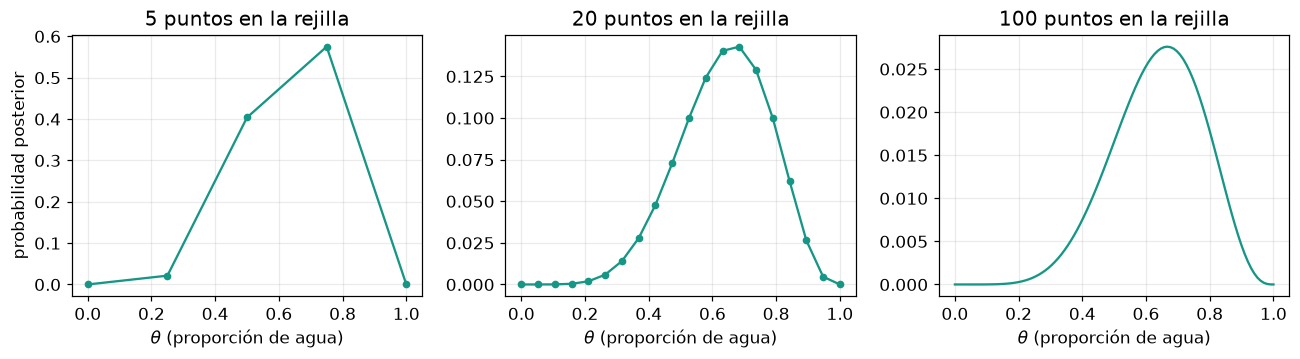

In [26]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, m in zip(axes, [5, 20, 100]):
    theta, prior, ver, post = posterior_rejilla(m, prior_uniforme, w, n)
    ax.plot(theta, post, "-o", color=C_TEAL, ms=4 if m <= 20 else 0, lw=1.5)
    ax.set_title(f"{m} puntos en la rejilla")
    ax.set_xlabel(r"$\theta$ (proporción de agua)")
axes[0].set_ylabel("probabilidad posterior")
plt.tight_layout(); plt.show()

La **forma** se estabiliza rápido: con 20 puntos ya se ve la curva. Pero miren el eje vertical de cada panel. Algo raro está pasando con la **altura**.

### Trampa clásica: probabilidad contra densidad

Si mi rejilla tiene $m$ puntos y las probabilidades suman 1, entonces conforme $m$ crece, cada punto se lleva **menos** probabilidad. La altura de la curva depende de cuántos puntos escogí, lo cual es absurdo como descripción de mi creencia sobre el globo.

La cantidad que no depende de la rejilla es la **densidad**: probabilidad dividida entre el ancho de cada celda, $\Delta\theta$. Es exactamente la distinción entre pmf y pdf de la Parte 0 del curso.

In [27]:
print(f"{'puntos':>7} {'altura máx (prob)':>18} {'altura máx (densidad)':>22} {'P(theta > 0.5)':>15}")
for m in [5, 20, 100, 1000, 10000]:
    theta, prior, ver, post = posterior_rejilla(m, prior_uniforme, w, n)
    delta = theta[1] - theta[0]
    densidad = post / delta
    print(f"{m:>7} {post.max():>18.5f} {densidad.max():>22.4f} {post[theta > 0.5].sum():>15.4f}")

 puntos  altura máx (prob)  altura máx (densidad)  P(theta > 0.5)
      5            0.57492                 2.2997          0.5749
     20            0.14283                 2.7139          0.8293
    100            0.02759                 2.7313          0.8282
   1000            0.00273                 2.7313          0.8281
  10000            0.00027                 2.7313          0.8281


Tres lecciones en esa tablita:

- La columna de **probabilidad** se va a cero conforme la rejilla se hace fina. La de **densidad** se estabiliza alrededor de $2.73$. Una densidad mayor que 1 no tiene nada de raro: no es una probabilidad.
- Las preguntas de verdad, como $P(\theta > 0.5 \mid \text{datos})$, **también** se estabilizan: alrededor de $0.828$. Esa es la respuesta que buscamos; la rejilla es solo la herramienta para calcularla. (Con 5 puntos sale $0.575$, porque una rejilla tan gruesa simplemente no alcanza a describir la creencia.)
- Muy pronto veremos que para este modelo existe una fórmula cerrada que da ese $0.828$ sin rejilla.

Una comprobación más, que ya vimos en las slides: **la verosimilitud no es una distribución sobre $\theta$.**

In [28]:
theta, prior, ver, post = posterior_rejilla(10001, prior_uniforme, w, n)
delta = theta[1] - theta[0]
print(f"Suma de la verosimilitud en la rejilla:          {ver.sum():9.2f}   (depende de la rejilla)")
print(f"Integral de la verosimilitud (suma x delta):     {(ver * delta).sum():9.4f}   (no da 1)")
print(f"Suma del posterior en la rejilla:                {post.sum():9.4f}   (sí es una distribución)")

Suma de la verosimilitud en la rejilla:            1000.00   (depende de la rejilla)
Integral de la verosimilitud (suma x delta):        0.1000   (no da 1)
Suma del posterior en la rejilla:                   1.0000   (sí es una distribución)


La verosimilitud integra $0.1$ (que es $1/(n+1)$, por cierto). Es una función de $\theta$ que mide qué tan bien explica cada valor los datos; para volverla distribución hay que multiplicarla por un prior y normalizar.

### El prior importa (y a veces demasiado)

McElreath propone dos priors alternativos para el globo. **Antes de correr**, piensen qué sabe o qué cree quien usa cada uno:

- **escalón**: "es imposible que haya menos de la mitad de agua" (prior cero para $\theta < 0.5$);
- **pico en 0.5**: "creo que debe ser más o menos mitad y mitad", $\;p(\theta)\propto e^{-5|\theta-0.5|}$.

> La alternativa de escalón, para obtener su distribución se debe multiplicar por el prior, pero esto lo concentraría en valores altos. Mientras que el pico en 0.5 cree que lo más probable es mitad y mitad, por lo que se mantendrá cerca de 0.5

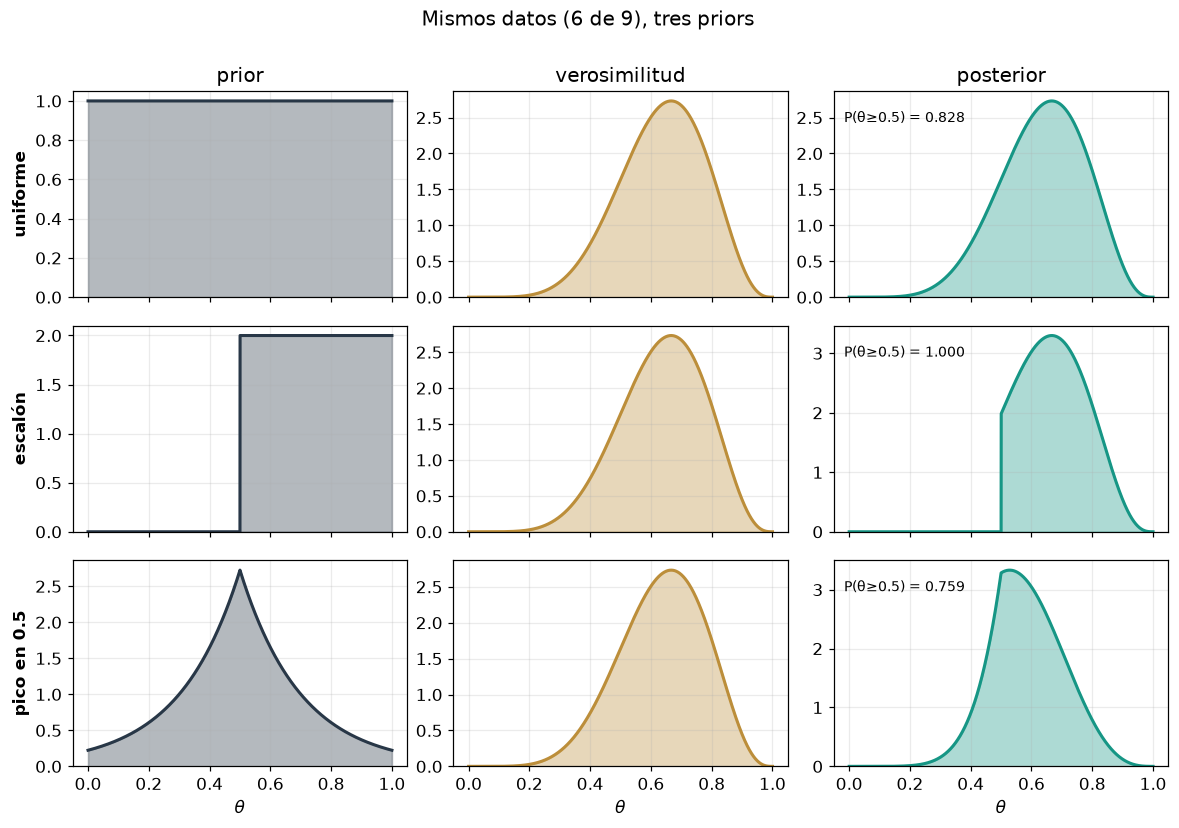

In [29]:
priors = {
    "uniforme":       prior_uniforme,
    "escalón":        lambda t: (t >= 0.5).astype(float),
    "pico en 0.5":    lambda t: np.exp(-5 * np.abs(t - 0.5)),
}

fig, axes = plt.subplots(3, 3, figsize=(11, 7.5), sharex=True)
for fila, (nombre, pf) in enumerate(priors.items()):
    theta, prior, ver, post = posterior_rejilla(10001, pf, w, n)
    delta = theta[1] - theta[0]
    prior_dens = prior / (prior.sum() * delta)
    ver_esc    = ver / (ver.sum() * delta)       # reescalada solo para dibujarla
    post_dens  = post / delta
    for col, (y, c, t) in enumerate([(prior_dens, C_SLATE, "prior"),
                                     (ver_esc,    C_GOLD,  "verosimilitud"),
                                     (post_dens,  C_TEAL,  "posterior")]):
        ax = axes[fila, col]
        ax.fill_between(theta, y, color=c, alpha=0.35); ax.plot(theta, y, color=c, lw=2)
        ax.set_ylim(bottom=0)
        if fila == 0: ax.set_title(t)
        if col == 0:  ax.set_ylabel(nombre, fontsize=11, fontweight="bold")
    p_mayor = post[theta >= 0.5].sum()
    axes[fila, 2].text(0.03, 0.85, f"P(θ≥0.5) = {p_mayor:.3f}", transform=axes[fila, 2].transAxes, fontsize=9)
for ax in axes[-1]: ax.set_xlabel(r"$\theta$")
fig.suptitle("Mismos datos (6 de 9), tres priors", y=1.0)
plt.tight_layout(); plt.show()

**¿Qué pasó?**

- La verosimilitud (columna del centro) es **la misma** en los tres renglones: los datos no cambian.
- Con el **pico en 0.5**, el posterior queda jalado hacia la mitad. Quien creía "mitad y mitad" sigue creyéndolo un poco, aunque los datos lo muevan.
- Con el **escalón**, el posterior es **exactamente cero** para $\theta<0.5$, y lo va a seguir siendo **sin importar cuántos datos lleguen**: cero por lo que sea es cero. Es la respuesta a la pregunta del dado sobre el prior $P(H_C)=0$. Se le conoce como la *regla de Cromwell*: no le asignes probabilidad cero a nada que no sea lógicamente imposible.

**Pregunta para el grupo.** ¿Es irracional el prior escalón? ¿En qué situación sería perfectamente razonable? ¿Qué arriesgas si te equivocas?

> El prior escalón es irracional en casos en donde efectivamente no hay manera de tener un mecanismo que garantiza que hay más agua que tierra. El riesgo de equivocarse es grave debido a la probabilidad, donde ningún dato puede corregir la distribución. 

### Ver aprender al modelo, lanzamiento por lanzamiento

Igual que con el dado, podemos ir actualizando con cada lanzamiento. Para un solo lanzamiento la verosimilitud es muy simple: $\theta$ si salió agua y $1-\theta$ si salió tierra. En cada panel, la curva punteada es la creencia **antes** del lanzamiento y la sólida la de **después**.

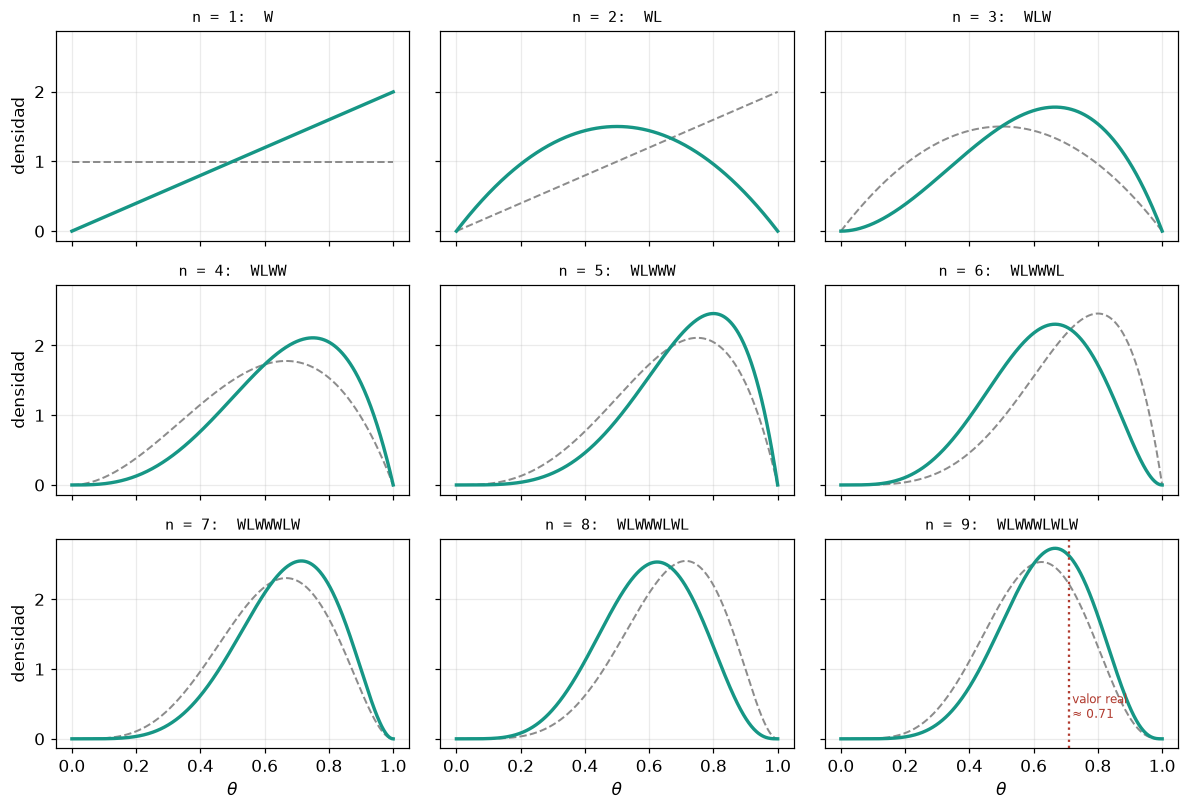

¿Secuencial = de golpe? True


In [30]:
theta = np.linspace(0, 1, 501)
delta = theta[1] - theta[0]
creencia = np.ones_like(theta); creencia /= creencia.sum()      # empezamos con prior uniforme

fig, axes = plt.subplots(3, 3, figsize=(11, 7.5), sharex=True, sharey=True)
for i, (ax, dato) in enumerate(zip(axes.flat, lanzamientos)):
    antes = creencia.copy()
    ver_un_lanz = theta if dato == "W" else (1 - theta)            # verosimilitud de UN lanzamiento
    creencia = ver_un_lanz * creencia; creencia /= creencia.sum()  # multiplicar y normalizar
    ax.plot(theta, antes / delta, "--", color="0.55", lw=1.3)
    ax.plot(theta, creencia / delta, color=C_TEAL, lw=2.2)
    vistos = "".join(lanzamientos[:i + 1])
    ax.set_title(f"n = {i+1}:  {vistos}", fontsize=10, family="monospace")
for ax in axes[-1]: ax.set_xlabel(r"$\theta$")
for ax in axes[:, 0]: ax.set_ylabel("densidad")
axes.flat[-1].axvline(0.71, color=C_WARN, ls=":", lw=1.5)
axes.flat[-1].text(0.72, 0.3, "valor real\n≈ 0.71", color=C_WARN, fontsize=8)
plt.tight_layout(); plt.show()

# Comprobación: ¿coincide con hacer todo de golpe?
_, _, _, post_lote = posterior_rejilla(501, prior_uniforme, w, n)
print("¿Secuencial = de golpe?", np.allclose(creencia, post_lote))

Observen:

- Cada **W** empuja la curva a la derecha; cada **L** la empuja a la izquierda.
- Con cada dato la curva se hace más **angosta**: la incertidumbre baja. Pero con 9 lanzamientos sigue bastante ancha, y eso es honesto: 9 datos no dan para mucho.
- El primer panel es interesante: después de ver una sola W, el valor $\theta = 0$ ya es imposible (vimos agua), y la creencia es una rampa.
- En la vida real la superficie de la Tierra es cerca de 71% agua. Nosotros lo sabemos; el modelo solo sabe lo que le dieron.

### Con la distribución en la mano, cualquier pregunta tiene respuesta

Esta es la ganancia de tener una distribución completa en vez de un solo número: cualquier pregunta sobre $\theta$ se contesta **sumando** el posterior sobre la región que interesa.

In [31]:
theta, prior, ver, post = posterior_rejilla(10001, prior_uniforme, w, n)

print(f"Valor más creíble (máximo del posterior):  {theta[post.argmax()]:.3f}   (igual al MLE, 6/9)")
print(f"P(theta > 0.5 | datos)                  =  {post[theta > 0.5].sum():.3f}")
print(f"P(0.6 < theta < 0.8 | datos)            =  {post[(theta > 0.6) & (theta < 0.8)].sum():.3f}")
print(f"P(theta > 0.9 | datos)                  =  {post[theta > 0.9].sum():.3f}")

Valor más creíble (máximo del posterior):  0.667   (igual al MLE, 6/9)
P(theta > 0.5 | datos)                  =  0.828
P(0.6 < theta < 0.8 | datos)            =  0.497
P(theta > 0.9 | datos)                  =  0.013


Recuerden la lámina "Las preguntas que se quedaron afuera": *¿cuál es la probabilidad de que la tasa esté entre 0.6 y 0.8?* El marco frecuentista no puede contestarla. Aquí es una suma.


## Parte 4. Laplace y los nacimientos de París: datos reales y enormes

Este ejemplo viene de BDA3 (cap. 2) y es histórico. Pierre-Simon Laplace, en el siglo XVIII, analizó los registros de bautizos en París entre 1745 y 1770:

- **241,945 niñas**
- **251,527 niños**

Su pregunta: si $\theta$ es la probabilidad de que un nacimiento sea niña, ¿qué tan seguros podemos estar de que $\theta < 0.5$? Es la misma estructura del globo (éxitos de $n$ intentos), pero con medio millón de intentos.

> Con esos datos, podemos asumir que la proporción observada de niñas queda por debajo de 0.5, lo cual se refuerza por el tamaño de la muestra. Con eso en mente, podemos confiar en que refleja bien a la población que deseamos estudiar.

In [32]:
ninas, ninos = 241_945, 251_527
n_par = ninas + ninos
print(f"Nacimientos totales: {n_par:,}")
print(f"Proporción de niñas: {ninas / n_par:.5f}")

Nacimientos totales: 493,472
Proporción de niñas: 0.49029


### Intento ingenuo

Hagamos lo mismo que con el globo, con la fórmula de la verosimilitud escrita a mano. **Antes de correr:** ¿qué esperan?

In [33]:
print("0.49 ** 241945        =", 0.49 ** ninas)
print("0.51 ** 251527        =", 0.51 ** ninos)

theta_ing = np.linspace(0.01, 0.99, 99)
ver_ing = theta_ing ** ninas * (1 - theta_ing) ** ninos
print("\nVerosimilitud ingenua en toda la rejilla: ¿algún valor distinto de cero?", (ver_ing > 0).any())
with np.errstate(invalid="ignore"):
    print("Posterior ingenuo (0/0):", (ver_ing / ver_ing.sum())[:5], "...")

0.49 ** 241945        = 0.0
0.51 ** 251527        = 0.0

Verosimilitud ingenua en toda la rejilla: ¿algún valor distinto de cero? False
Posterior ingenuo (0/0): [nan nan nan nan nan] ...


Todo da cero, y el posterior da `nan` (cero entre cero). El número más pequeño que la computadora puede representar en punto flotante ronda $10^{-308}$, y aquí estamos multiplicando 493 mil probabilidades. Ya lo habíamos olido en el dado, con verosimilitudes del orden de $10^{-150}$.

### La solución: trabajar en logaritmos

Tres ideas, todas simples:

1. En lugar de multiplicar, **sumamos logaritmos**: $\log(\text{prior}\times\text{ver}) = \log\text{prior} + \log\text{ver}$, y $\log\left[\theta^{y}(1-\theta)^{n-y}\right] = y\log\theta + (n-y)\log(1-\theta)$. Eso es un número manejable, del orden de $-340{,}000$.
2. El coeficiente binomial $\binom{n}{y}$ no depende de $\theta$, así que lo **tiramos**: se cancela al normalizar. Es el "$\propto$" de la regla de Bayes trabajando a nuestro favor.
3. Antes de regresar de logaritmos, **restamos el máximo**. Eso equivale a dividir todo entre una constante, que también se cancela al normalizar. Así el punto más alto vale $e^0 = 1$ y nada se va a cero innecesariamente.

Son exactamente "multiplicar y normalizar", escritos de forma que la computadora no se ahogue. Así es como lo hace cualquier software bayesiano real, PyMC incluido.

In [34]:
theta_L = np.linspace(0, 1, 1_000_001)[1:-1]     # sin 0 ni 1, para no evaluar log(0)
delta_L = theta_L[1] - theta_L[0]

log_ver   = ninas * np.log(theta_L) + ninos * np.log(1 - theta_L)   # sin el coeficiente binomial
log_prior = np.zeros_like(theta_L)                                   # uniforme: log(1) = 0
log_post  = log_ver + log_prior                                      # multiplicar = sumar logs

print(f"log-posterior (sin normalizar): va de {log_post.min():,.0f} a {log_post.max():,.0f}")

post_L = np.exp(log_post - log_post.max())       # restar el máximo antes de exponenciar
post_L /= post_L.sum()                           # normalizar
print(f"Suma del posterior: {post_L.sum():.6f}")

log-posterior (sin normalizar): va de -3,474,974 a -341,956
Suma del posterior: 1.000000


Media posterior de theta:        0.49029
Desviación estándar posterior:   0.00071
P(theta >= 0.5 | datos)        = 1.16e-42
Laplace (BDA3) reporta           ≈ 1.15e-42


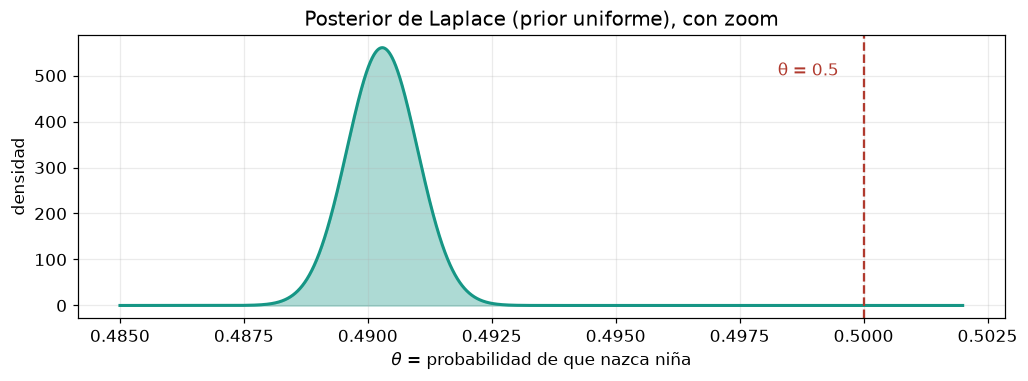

In [35]:
media = (theta_L * post_L).sum()
de    = np.sqrt(((theta_L - media) ** 2 * post_L).sum())
p_mayor = post_L[theta_L >= 0.5].sum()

print(f"Media posterior de theta:        {media:.5f}")
print(f"Desviación estándar posterior:   {de:.5f}")
print(f"P(theta >= 0.5 | datos)        = {p_mayor:.2e}")
print( "Laplace (BDA3) reporta           ≈ 1.15e-42")

zoom = (theta_L > 0.485) & (theta_L < 0.502)
fig, ax = plt.subplots(figsize=(9.5, 3.6))
ax.fill_between(theta_L[zoom], post_L[zoom] / delta_L, color=C_TEAL, alpha=0.35)
ax.plot(theta_L[zoom], post_L[zoom] / delta_L, color=C_TEAL, lw=2)
ax.axvline(0.5, color=C_WARN, ls="--", lw=1.5)
ax.text(0.4995, ax.get_ylim()[1] * 0.85, "θ = 0.5", color=C_WARN, ha="right")
ax.set_xlabel(r"$\theta$ = probabilidad de que nazca niña"); ax.set_ylabel("densidad")
ax.set_title("Posterior de Laplace (prior uniforme), con zoom")
plt.tight_layout(); plt.show()

Laplace concluyó que la probabilidad de que $\theta \geq 0.5$ es del orden de $10^{-42}$. Nuestra rejilla da el mismo orden (la pequeña diferencia en el segundo dígito viene de aproximar una integral con una suma). En palabras: **estamos prácticamente seguros de que nacen menos niñas que niños**, y el valor de $\theta$ está en un rango de unas milésimas alrededor de $0.490$.

Noten la escala del eje horizontal: toda la creencia vive entre $0.487$ y $0.493$. Comparen con el globo, donde la creencia se extendía por casi todo el intervalo $[0,1]$.

### Una advertencia sobre las rejillas

Usamos un millón de puntos. ¿Por qué tantos? Porque la rejilla tiene que ser **más fina que el ancho del posterior** (aquí, unas milésimas). Miren qué pasa con la rejilla de 101 puntos que nos sirvió para el globo:

In [36]:
theta_g = np.linspace(0, 1, 101)[1:-1]
lp = ninas * np.log(theta_g) + ninos * np.log(1 - theta_g)
pg = np.exp(lp - lp.max()); pg /= pg.sum()
orden = np.argsort(pg)[::-1][:3]
for i in orden:
    print(f"theta = {theta_g[i]:.2f}   probabilidad = {pg[i]:.6f}")

theta = 0.49   probabilidad = 1.000000
theta = 0.50   probabilidad = 0.000000
theta = 0.48   probabilidad = 0.000000


La rejilla gruesa pone casi el 100% de la probabilidad en el único punto $0.49$. No está "mal", pero perdimos toda la forma de la creencia. Con un parámetro esto se arregla poniendo más puntos; con 10 parámetros, una rejilla de 1000 puntos por eje tendría $1000^{10}$ puntos. Por eso, en la última sesión del bloque, vamos a necesitar otros métodos.

### ¿Y el prior? Con medio millón de datos, casi da igual

Pongamos a tres analistas con priors muy distintos:

- **uniforme**: no sé nada;
- **pico en 0.5**: "debe ser mitad y mitad", como en el globo;
- **terco**: alguien convencido de que nacen **más niñas**, con un prior normal centrado en $0.6$ y desviación $0.02$. Para esta persona, $\theta = 0.49$ está a más de cinco desviaciones de lo que cree.

**Antes de correr:** ¿cuánto se moverá el posterior del analista terco?

> El terco empieza con un prior muy distinto (centrado en 0.6), pero al ver tantos datos que apuntan a ≈0.49, la verosimilitud domina y se mueve hacia ese valor. La estadística bayesiana actualiza creencias con la evidencia, y con tantos datos el prior termina pesando muy poco.

        prior  media posterior  P(theta >= 0.5)
     uniforme          0.49029         1.16e-42
  pico en 0.5          0.49029         1.21e-42
  terco (0.6)          0.49043         1.47e-41


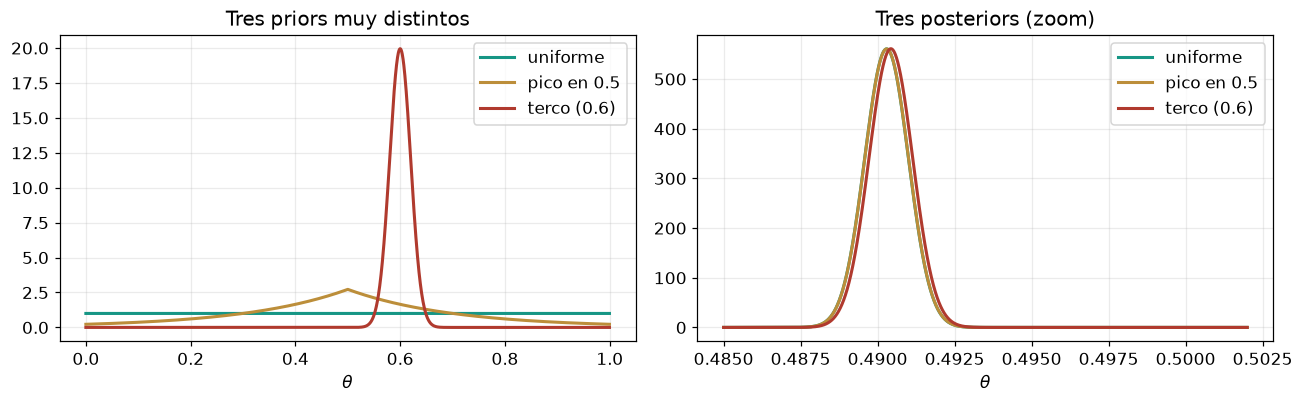

In [37]:
log_priors = {
    "uniforme":    np.zeros_like(theta_L),
    "pico en 0.5": -5 * np.abs(theta_L - 0.5),
    "terco (0.6)": stats.norm(0.6, 0.02).logpdf(theta_L),
}
colores = [C_TEAL, C_GOLD, C_WARN]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
print(f"{'prior':>13} {'media posterior':>16} {'P(theta >= 0.5)':>16}")
for (nombre, lpr), c in zip(log_priors.items(), colores):
    pr = np.exp(lpr - lpr.max()); pr /= pr.sum()
    lp = log_ver + lpr
    po = np.exp(lp - lp.max()); po /= po.sum()
    axes[0].plot(theta_L[::500], pr[::500] / delta_L, color=c, lw=2, label=nombre)
    axes[1].plot(theta_L[zoom], po[zoom] / delta_L, color=c, lw=2, label=nombre)
    print(f"{nombre:>13} {(theta_L * po).sum():>16.5f} {po[theta_L >= 0.5].sum():>16.2e}")
axes[0].set_title("Tres priors muy distintos"); axes[0].set_xlabel(r"$\theta$"); axes[0].legend()
axes[1].set_title("Tres posteriors (zoom)");    axes[1].set_xlabel(r"$\theta$"); axes[1].legend()
plt.tight_layout(); plt.show()

Las tres curvas del panel derecho están **una encima de otra**. El terco movió su media en la cuarta cifra decimal. Con medio millón de observaciones, la verosimilitud es tan angosta que cualquier prior razonable (y hasta uno bastante irrazonable) queda aplastado.

Moraleja: las discusiones sobre "qué prior usar" importan **cuando hay pocos datos**. Que es, por cierto, la situación de casi cualquier problema interesante: un producto nuevo en 10 tiendas, un paciente raro, un experimento caro.


## Parte 5. Una clínica pequeña: el contexto entra por el prior

Una clínica pequeña registra **20 nacimientos** en una semana: **14 niñas**. El estimador de máxima verosimilitud dice $\hat\theta = 0.70$. ¿Le creemos?

Tres analistas:

- **A, sin contexto**: prior uniforme.
- **B, con contexto razonable**: sabe que en poblaciones humanas la proporción de niñas al nacer anda alrededor de $0.49$ y varía poco entre poblaciones. Usa un prior normal centrado en $0.49$ con desviación $0.02$ (o sea, le da 95% de probabilidad a que $\theta$ esté entre $0.45$ y $0.53$).
- **C, dogmático**: toma el posterior de Laplace **tal cual** como su prior. Está diciendo: "esta clínica es idéntica a París en 1770".

**Antes de correr:** ordenen a los tres analistas según qué tanto creen, después de los datos, que en esta clínica nacen más niñas que niños.

> 1) A
> 2) C
> 3) B

                   analista  media prior  media posterior  P(theta > 0.5)
                A: uniforme        0.500            0.682           0.961
  B: contexto N(0.49, 0.02)        0.490            0.497           0.430
     C: dogmático (Laplace)        0.490            0.490           0.000


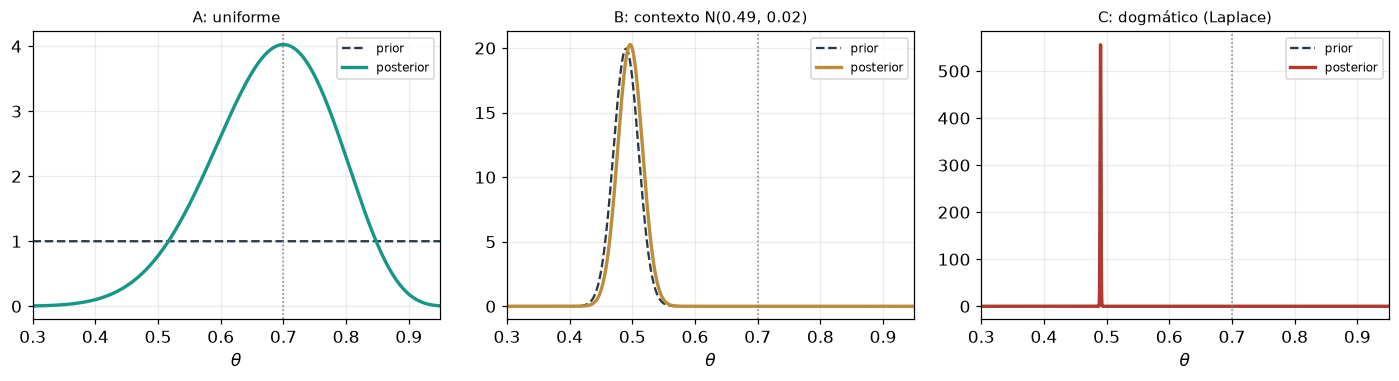

In [38]:
y_cl, n_cl = 14, 20
log_ver_cl = y_cl * np.log(theta_L) + (n_cl - y_cl) * np.log(1 - theta_L)

priors_clinica = {
    "A: uniforme":            np.zeros_like(theta_L),
    "B: contexto N(0.49, 0.02)": stats.norm(0.49, 0.02).logpdf(theta_L),
    "C: dogmático (Laplace)": log_post - log_post.max(),     # el posterior de la Parte 4, en logs
}

def resume(log_prior, log_ver):
    lp = log_prior + log_ver
    po = np.exp(lp - lp.max()); po /= po.sum()
    return po

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
print(f"{'analista':>27} {'media prior':>12} {'media posterior':>16} {'P(theta > 0.5)':>15}")
for ax, (nombre, lpr), c in zip(axes, priors_clinica.items(), colores):
    pr = resume(lpr, 0)
    po = resume(lpr, log_ver_cl)
    paso = 200
    ax.plot(theta_L[::paso], pr[::paso] / delta_L, "--", color=C_SLATE, lw=1.5, label="prior")
    ax.plot(theta_L[::paso], po[::paso] / delta_L, color=c, lw=2.2, label="posterior")
    ax.axvline(0.70, color="0.5", ls=":", lw=1); ax.set_xlim(0.3, 0.95)
    ax.set_title(nombre, fontsize=10); ax.set_xlabel(r"$\theta$"); ax.legend(fontsize=8)
    print(f"{nombre:>27} {(theta_L*pr).sum():>12.3f} {(theta_L*po).sum():>16.3f} {po[theta_L > 0.5].sum():>15.3f}")
plt.tight_layout(); plt.show()

**¿Qué pasó?**

- **A** le cree casi todo a los 20 datos: queda bastante convencido de que en esa clínica nacen más niñas.
- **B** se mueve un poco hacia arriba, pero sigue pensando que lo más probable es una proporción normal y que 14 de 20 fue, en buena parte, suerte. Veinte nacimientos son muy pocos para contradecir lo que se sabe de miles de poblaciones.
- **C** no se mueve **nada**. Su prior es tan angosto que 20 datos no le hacen cosquillas (en su panel, el prior punteado queda escondido debajo del posterior: son prácticamente la misma curva).

La línea punteada vertical marca $0.70$, el MLE.

¿Quién tiene razón? Depende de **qué tan parecida es esta clínica a lo que cada prior asume**. Si es una clínica cualquiera, B está haciendo lo sensato y A se está dejando llevar por el ruido. Pero si la clínica atiende a una población especial (por ejemplo, embarazos con alguna condición médica particular), entonces el supuesto de C, "esta clínica es París", es justo el que habría que discutir. Esa discusión, por cierto, es exactamente el caso de *placenta previa* que vamos a trabajar en clase.

Es la misma lección del corrector ortográfico con "radom": **el prior es la puerta por donde entra el contexto**, y como está escrito explícitamente, se puede discutir.

### ¿Cuántos datos harían falta para que todos coincidieran?

Supongamos que la clínica siguiera registrando nacimientos con la misma proporción de 70% niñas.

In [39]:
print(f"{'nacimientos':>12} | {'media posterior A':>17} {'B':>7} {'C':>7}")
for n_cl2 in [20, 200, 2_000, 20_000]:
    y_cl2 = int(0.7 * n_cl2)
    lv = y_cl2 * np.log(theta_L) + (n_cl2 - y_cl2) * np.log(1 - theta_L)
    medias = [(theta_L * resume(lpr, lv)).sum() for lpr in priors_clinica.values()]
    print(f"{n_cl2:>12,} | {medias[0]:>17.3f} {medias[1]:>7.3f} {medias[2]:>7.3f}")

 nacimientos | media posterior A       B       C
          20 |             0.682   0.497   0.490
         200 |             0.698   0.541   0.490
       2,000 |             0.700   0.654   0.491
      20,000 |             0.700   0.695   0.498


- **B** termina siguiendo a los datos, aunque con calma: con 200 nacimientos apenas sube a $0.54$, con 2,000 ya está en $0.65$ y con 20,000 prácticamente coincide con A. Un buen prior informativo **cede** cuando la evidencia es contundente.
- **C** casi no se mueve ni con 20,000 nacimientos, porque su prior "vale" lo mismo que medio millón de observaciones. Si de verdad vieras 14,000 niñas en 20,000 nacimientos, querrías que tu modelo lo notara. Un prior dogmático es peligroso precisamente porque te vuelve sordo a la evidencia.

**Pregunta para el grupo.** El analista B usó desviación $0.02$. ¿Qué pasaría con $0.005$? ¿Y con $0.2$? ¿Con cuál de los otros dos analistas se parecería en cada caso?

> Con desviación 0.005, el prior de B es muy estrecho, así que está muy convencido de que θ ≈ 0.6 y se movería mucho más lento, pareciéndose más a C (el dogmático). Con desviación 0.2, el prior es muy ancho y B está poco convencido, así que cedería rápido ante los datos y se parecería más a A (el uniforme). 


## Cierre: lo que vimos, en una tabla

| Idea | Dónde la vimos |
|---|---|
| El parámetro es fijo; la distribución describe **lo que sabemos** de él | el dado (ya estaba cargado desde el principio) |
| posterior $\propto$ verosimilitud $\times$ prior, y normalizar | en todas las partes |
| La verosimilitud es **contar** maneras de producir los datos | las canicas |
| El posterior de hoy es el prior de mañana; el orden no importa | dado, canicas, globo |
| Las hipótesis se vuelven **valores de un parámetro**, y la tabla se vuelve rejilla | canicas, globo |
| Probabilidad en la rejilla contra **densidad** | el globo |
| Un prior con ceros nunca se recupera (regla de Cromwell) | el globo con escalón |
| Con la distribución en la mano, cualquier pregunta es una suma | el globo, Laplace |
| En la computadora: **logaritmos** y restar el máximo | Laplace |
| Con muchos datos el prior casi no importa; con pocos, importa mucho | Laplace contra la clínica |
| El prior es la puerta del contexto, y por eso se debe discutir | la clínica (y "radom") |

**Para pensar antes de la siguiente sesión** (no se entrega):

1. En el dado, el analista confiado tardó unos 120 tiros en convencerse. Si un amigo te propone apostar con un dado, ¿qué prior usarías tú, y por qué?
2. En el globo, el posterior después de 9 lanzamientos sigue siendo ancho. Sin calcular nada: ¿cómo creen que se vería después de 900 lanzamientos con la misma proporción de agua?
3. Laplace concluyó algo con una seguridad de $1 - 10^{-42}$. ¿Qué supuesto del modelo, que no aparece en ningún número, tendría que fallar para que esa conclusión estuviera mal? (Pista: piensen en qué significa que los nacimientos sean "como lanzar el mismo globo" una y otra vez.)

**Lecturas.** McElreath, *Statistical Rethinking* (2a ed.), cap. 2 completo: es corto, muy ameno, y cubre las Partes 2 y 3 de este notebook. BDA3, §2.1 a §2.4, para Laplace y el caso de placenta previa.